# 01 – Exploration de Best Books Ever (P1-02)

Objectif : mesurer ce que le dataset permet réellement (taux de remplissage, langues, genres, pages, descriptions, cadre) pour fonder les règles de nettoyage. Les chiffres alimentent [docs/dataset.md](../../docs/dataset.md).

La dernière section appelle le cas d'usage `PrepareCatalog` : le notebook ne recode pas la logique de nettoyage.

In [1]:
import ast

import matplotlib.pyplot as plt
import pandas as pd

from book_recommender.main.settings import Settings

settings = Settings.from_env()
RAW = settings.raw_dir / "books_1.Best_Books_Ever.csv"

# Une teinte (série unique), grille et axes discrets.
BAR, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#d6d5d0",
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "figure.dpi": 110,
    }
)


def hbar(series, title, xlabel, fmt="{:.0%}"):
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(series) + 0.8))
    ax.barh(series.index[::-1], series.values[::-1], color=BAR, height=0.7)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(series.values[::-1]):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=MUTED)
    plt.tight_layout()
    plt.show()


df = pd.read_csv(RAW)
df.shape

(52478, 25)

## Taux de remplissage par colonne

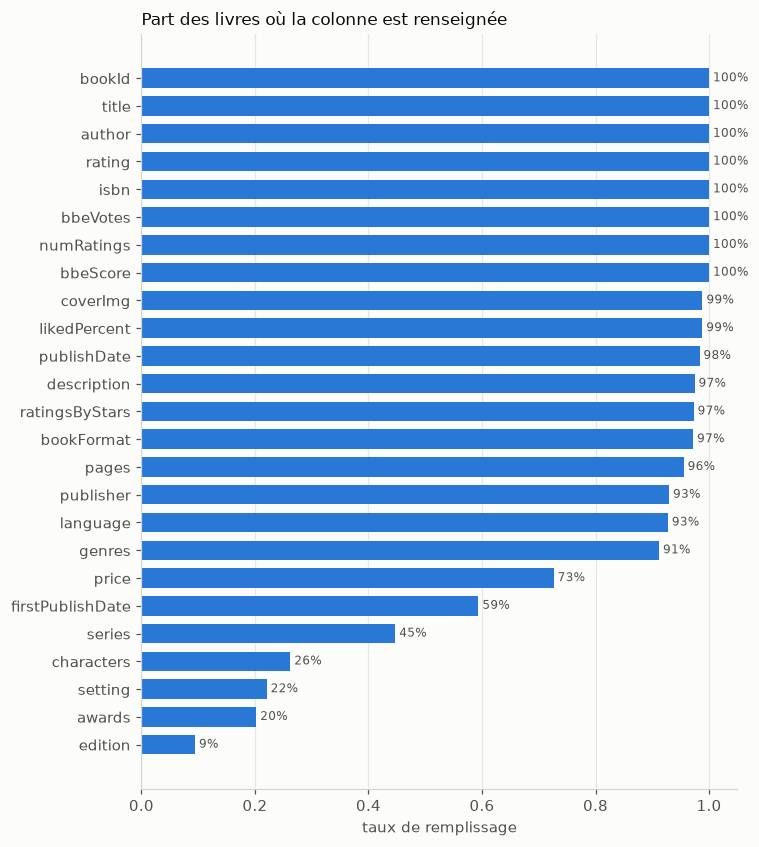

In [2]:
filled = df.replace({"[]": None, "": None}).notna().mean().sort_values(ascending=False)
hbar(filled, "Part des livres où la colonne est renseignée", "taux de remplissage")

`setting` et `characters` paraissent pleins mais valent souvent `[]` (liste vide) : on les compte ici comme vides.

## Langues

In [3]:
langs = df.language.value_counts(dropna=False)
print(f"sans langue : {df.language.isna().mean():.1%}")
langs.head(10).to_frame("livres")

sans langue : 7.3%


,livres
language,
English,42661
NaN,3806
Arabic,1038
Spanish,687
French,579
German,528
Indonesian,371
Portuguese,363
Italian,255


## Genres et part de fiction

tag Fiction : 60.3% · tag Nonfiction : 15.7% · les deux : 0.0%
sans aucun genre : 8.8%


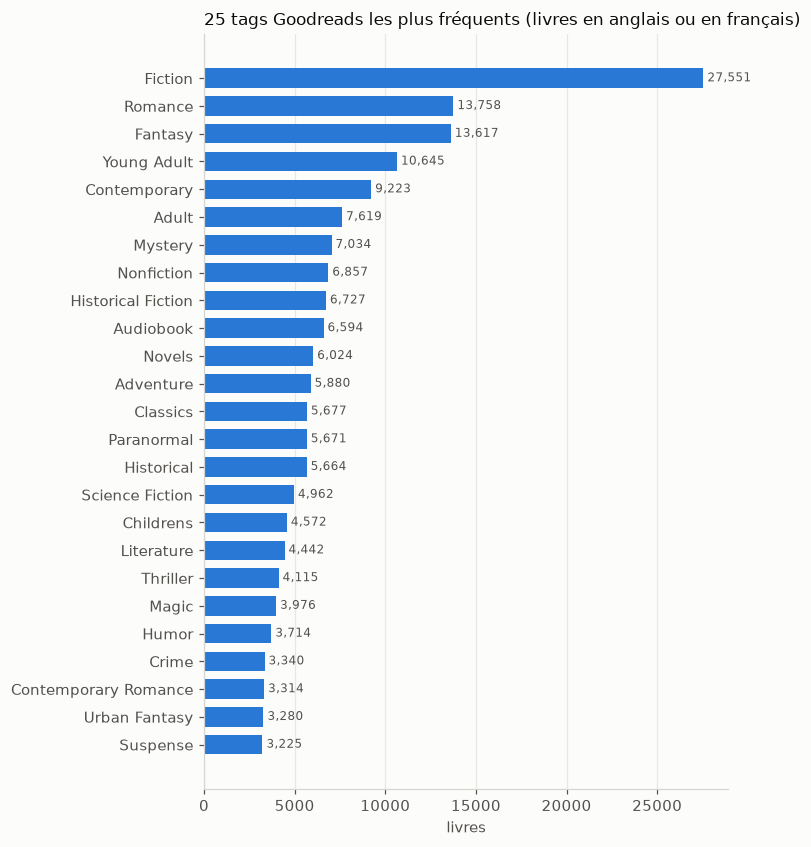

In [4]:
tags = df.genres.fillna("[]").apply(ast.literal_eval)
fiction = tags.apply(lambda t: "Fiction" in t)
nonfiction = tags.apply(lambda t: "Nonfiction" in t)
print(
    f"tag Fiction : {fiction.mean():.1%} · tag Nonfiction : {nonfiction.mean():.1%} · les deux : {(fiction & nonfiction).mean():.1%}"
)
print(f"sans aucun genre : {(tags.str.len() == 0).mean():.1%}")

en_fr = df.language.isin(["English", "French"])
top = tags[en_fr].explode().value_counts().head(25)
hbar(
    top,
    "25 tags Goodreads les plus fréquents (livres en anglais ou en français)",
    "livres",
    fmt="{:,.0f}",
)

« Fiction » ne figure que sur ~60 % des livres : une règle « fiction » fondée sur ce seul tag perdrait beaucoup de romans (fantasy, romance…). La règle retenue combine plusieurs tags de fiction et exclut « Nonfiction » (voir `catalog_filters` dans options.json).

## Nombre de pages

pages inconnues : 4.5% · < 10 pages : 293 · > 5000 : 11


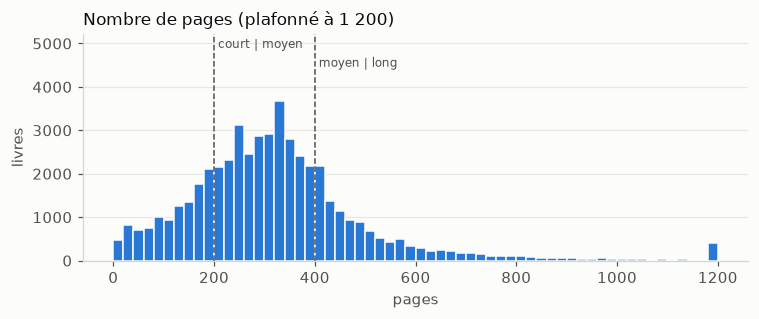

,count,mean,std,min,25%,50%,75%,max
pages,50131.0,329.0,252.0,0.0,210.0,304.0,392.0,14777.0


In [5]:
pages = pd.to_numeric(df.pages.astype(str).str.split().str[0], errors="coerce")
print(
    f"pages inconnues : {pages.isna().mean():.1%} · < 10 pages : {(pages < 10).sum()} · > 5000 : {(pages > 5000).sum()}"
)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(pages.clip(upper=1200).dropna(), bins=60, color=BAR, edgecolor=SURFACE, linewidth=1)
ax.set_ylim(top=ax.get_ylim()[1] * 1.35)
for i, (limit, label) in enumerate([(200, "court | moyen"), (400, "moyen | long")]):
    ax.axvline(limit, color=MUTED, linewidth=1, linestyle="--")
    ax.text(
        limit, ax.get_ylim()[1] * (0.98 - 0.08 * i), " " + label, fontsize=8, color=MUTED, va="top"
    )
ax.set_title("Nombre de pages (plafonné à 1 200)", loc="left", fontsize=11)
ax.set_xlabel("pages")
ax.set_ylabel("livres")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
pages.describe().round(0).to_frame("pages").T

## Longueur des descriptions

sans description : 2.5% · < 30 mots : 6.4%


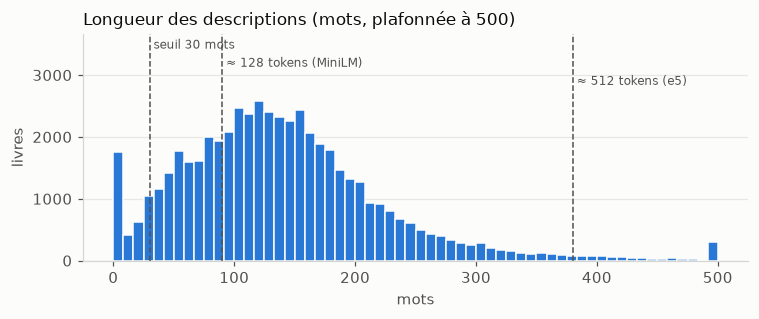

,0.05,0.25,0.50,0.75,0.95
mots,22.0,82.0,130.0,180.0,290.0


In [6]:
words = df.description.fillna("").str.split().str.len()
print(
    f"sans description : {df.description.isna().mean():.1%} · < 30 mots : {(words < 30).mean():.1%}"
)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(words.clip(upper=500), bins=60, color=BAR, edgecolor=SURFACE, linewidth=1)
ax.set_ylim(top=ax.get_ylim()[1] * 1.35)
for i, (limit, label) in enumerate(
    [(30, "seuil 30 mots"), (90, "≈ 128 tokens (MiniLM)"), (380, "≈ 512 tokens (e5)")]
):
    ax.axvline(limit, color=MUTED, linewidth=1, linestyle="--")
    ax.text(
        limit, ax.get_ylim()[1] * (0.98 - 0.08 * i), " " + label, fontsize=8, color=MUTED, va="top"
    )
ax.set_title("Longueur des descriptions (mots, plafonnée à 500)", loc="left", fontsize=11)
ax.set_xlabel("mots")
ax.set_ylabel("livres")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
words.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("mots").T

La médiane est de 130 mots : MiniLM (128 tokens, soit ≈ 90 mots) tronquerait plus de la moitié des descriptions ; e5-base (512 tokens) les lit presque toutes en entier. Les repères en tokens sont approximatifs (≈ 1,4 token par mot en anglais).

## Cadre (`setting`) : des lieux, pas des époques

In [7]:
settings_filled = df.setting[df.setting != "[]"]
has_time = settings_filled.str.contains(
    r"\b1[0-9]{3}\b|\b20[0-9]{2}\b|century", case=False, regex=True
)
print(
    f"setting renseigné : {len(settings_filled) / len(df):.1%} · avec une année ou un siècle : {has_time.sum()}"
)
settings_filled.sample(8, random_state=1).to_frame("setting")

setting renseigné : 22.1% · avec une année ou un siècle : 0


,setting
6755,"['California (United States)', 'France']"
2834,"['Ford County, Mississippi (United States)']"
3503,"['Pineville, New Jersey (United States)']"
2720,"['Brighton, England (United Kingdom)']"
22930,"['New York City, New York (United States)', 'C..."
24929,['Dublin (Ireland)']
23858,"['Toronto, Ontario (Canada)']"
50236,['Wonderland']


Le champ `setting` ne contient que des lieux. La SPEC prévoyait de l'utiliser pour la période : la période viendra donc entièrement de la classification zero-shot de la description (P1-12).

## Doublons et dates

In [8]:
print(
    f"bookId en double : {df.bookId.duplicated().sum()} · titre + auteur en double : {df.duplicated(['title', 'author']).sum()}"
)
df[["title", "firstPublishDate", "publishDate"]].dropna().sample(6, random_state=2)

bookId en double : 54 · titre + auteur en double : 88


,title,firstPublishDate,publishDate
10382,Shattered Souls,12/08/11,December 6th 2012
48278,The Tie That Binds,11/06/84,March 21st 2000
32470,The Girlfriend,12/06/91,September 1st 2004
30295,Mothering Sunday,04/19/16,April 26th 2016
40090,The Curse of Camp Cold Lake,06/06/97,June 1st 2005
5130,Undaunted Courage: The Pioneering First Missio...,02/15/96,October 6th 2003


`firstPublishDate` est au format MM/JJ/AA : le siècle est perdu (Jane Eyre, 1847, apparaît en « 47 »). L'année est reconstruite à partir de l'année de l'édition (`publishDate`), avec cette limite documentée.

## Résultat du nettoyage (cas d'usage `PrepareCatalog`)

In [9]:
from datetime import date

from book_recommender.catalog_preparation.adapters.csv_raw_book_source import CsvRawBookSource
from book_recommender.catalog_preparation.adapters.options_rules import load_catalog_rules
from book_recommender.catalog_preparation.application.prepare_catalog import (
    PrepareCatalog,
    PrepareCatalogRequest,
)


class KeepInMemory:
    books = []

    def write(self, books):
        KeepInMemory.books = list(books)


report = PrepareCatalog(
    CsvRawBookSource(RAW), KeepInMemory(), load_catalog_rules(settings.options_path)
)(PrepareCatalogRequest(current_year=date.today().year))

steps = pd.DataFrame(
    [{"étape": "entrée", "retirés": None, "restants": report.input_count}]
    + [{"étape": s.step, "retirés": s.removed, "restants": s.remaining} for s in report.steps]
)
print(
    f"sans genre normalisé : {report.without_genre} · sans nombre de pages : {report.without_pages}"
)
steps

sans genre normalisé : 387 · sans nombre de pages : 719


,étape,retirés,restants
0,entrée,NaN,52478
1,identifiant en double,54.0,52424
2,langue absente ou hors en/fr,9216.0,43208
3,pas de la fiction,11002.0,32206
4,"format exclu (BD, poésie, erotica)",3729.0,28477
5,description < 30 mots,923.0,27554
6,doublon titre + auteur,29.0,27525


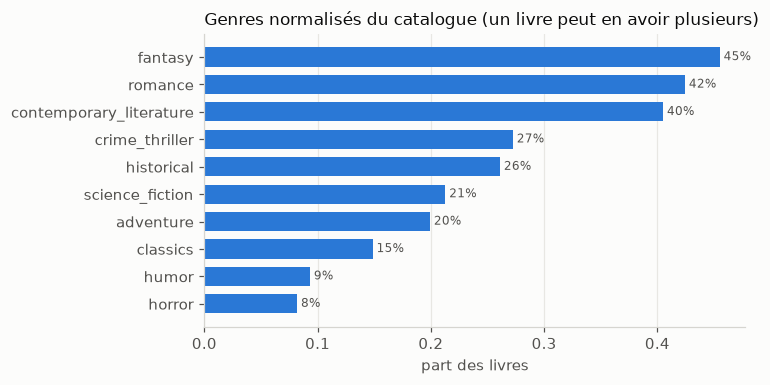

livres
langue      en       27165
            fr         360
âge minimum 18       17202
            13        6365
            0         3958
longueur    medium   16142
            long      6967
            short     3697
            NaN        719

In [10]:
catalog = pd.DataFrame([vars(b) for b in KeepInMemory.books])
genre_share = catalog.genres.explode().value_counts() / len(catalog)
hbar(
    genre_share,
    "Genres normalisés du catalogue (un livre peut en avoir plusieurs)",
    "part des livres",
)
pd.concat(
    {
        "langue": catalog.language.value_counts(),
        "âge minimum": catalog.min_age.value_counts(),
        "longueur": catalog.length_category.value_counts(dropna=False),
    }
).to_frame("livres")

## À retenir

- 27 525 livres de fiction en anglais ou en français, dont seulement 360 en français : le catalogue est quasi anglophone, d'où le SBERT multilingue.
- La part de fiction repose sur plusieurs tags, pas sur « Fiction » seul.
- `setting` ne donne pas d'époque : période par zero-shot.
- Descriptions médianes de 130 mots : argument pour e5-base (512 tokens) face à MiniLM (128).
- Années reconstruites, avec une erreur possible d'un siècle pour certains classiques.